Rilevamento RF: confronto tra classificatori classici e quantistici simulati

Questo notebook presenta uno studio sperimentale per la classificazione di segnali a radiofrequenza (RF) in due categorie: benigni (classe 0) e malevoli (classe 1).

L’obiettivo è confrontare le prestazioni di un classificatore classico Random Forest con tre approcci di classificazione quantistica simulata:

1. Random Forest (RF): baseline classica valutata con 5.000 e 20.000 campioni di addestramento.
2. VQE-inspired: classificatore variazionale basato su un circuito quantistico parametrizzato, ottimizzato mediante Adam.
3. QAOA-inspired: classificatore che alterna operatori di costo e mixer parametrizzati.
4. VQS-inspired: classificatore variazionale con aggiornamento del gradiente precondizionato da una stima diagonale della metrica quantistica.

I modelli utilizzano quattro feature selezionate e trasformate mediante un preprocessing comune. Le architetture quantistiche sono simulate con PennyLane e impiegano quattro qubit.

Per ridurre il rischio di data leakage, lo split del dataset impedisce che vettori di feature numericamente identici siano condivisi tra training, validation e test.

Il confronto viene effettuato su un test comune di 5.000 osservazioni, utilizzando metriche quali accuracy, precision, recall, F1-score, AUROC e numero di falsi positivi e falsi negativi.

Nota metodologica: i modelli quantistici sono simulati e rappresentano implementazioni inspired. I risultati non costituiscono una dimostrazione di vantaggio quantistico né garantiscono la generalizzazione a nuove acquisizioni RF indipendenti.

In [1]:
# Eseguire solo se le librerie non sono già installate.
%pip install -q pennylane scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

import pennylane as qml
from pennylane import numpy as pnp

SEED = 42
np.random.seed(SEED)
pnp.random.seed(SEED)
print('PennyLane:', qml.__version__)

PennyLane: 0.42.3


## 1. Configurazione e caricamento dati

Impostare `DATA_PATH` sul CSV. Il notebook cerca automaticamente colonne di etichetta comuni (`label`, `label_encoded`, `target`, `class`, `y`). Sono accettate etichette testuali come `benign`, `normal`, `malicious`, `attack`, oppure valori binari 0/1.

In [3]:
DATA_PATH = Path('output/split/train_dataset.csv')

TEST_SIZE = 0.20

MAX_QUBITS = 4
N_LAYERS = 2

TRAIN_STEPS = 500
BATCH_SIZE = 16

SEEDS = [42, 123, 2024, 2025, 2026]
SEED = 42

QUANTUM_TRAIN_SAMPLES = 5000
VALIDATION_SAMPLES = 1000
EVALUATION_SAMPLES = 5000

RF_TRAIN_SAMPLES = 20000

EVAL_EVERY = 20
PATIENCE_CHECKS = 10
VQS_METRIC_EVERY = 20

LABEL_CANDIDATES = [
    'label_encoded'
   
]

# Impostare il nome della colonna che identifica
# le acquisizioni RF indipendenti, se disponibile.
GROUP_COLUMN = None

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'Dataset non trovato: {DATA_PATH.resolve()}'
    )

df = pd.read_csv(DATA_PATH)

label_col = next(
    (c for c in LABEL_CANDIDATES if c in df.columns),
    None
)

if label_col is None:
    raise ValueError(
        f'Nessuna colonna etichetta trovata: {list(df.columns)}'
    )

print("Dataset:", DATA_PATH)
print("Dimensioni:", df.shape)
print("Label:", label_col)
print("Colonne:", df.columns.tolist())

display(df.head())

Dataset: output/split/train_dataset.csv
Dimensioni: (52752000, 10)
Label: label_encoded
Colonne: ['freq1', 'noise', 'max_magnitude', 'total_gain_db', 'base_pwr_db', 'rssi', 'relpwr_db', 'avgpwr_db', 'label', 'label_encoded']


,freq1,noise,max_magnitude,total_gain_db,base_pwr_db,rssi,relpwr_db,avgpwr_db,label,label_encoded
0,5805,-108,37,90,377,2,8,57,benign,0
1,5805,-102,52,68,393,9,9,47,benign,0
2,5805,-108,58,90,377,4,8,57,benign,0
3,5805,-102,52,68,393,11,10,49,benign,0
4,5805,-102,46,40,421,53,16,58,malicious,1


Controllo dei duplicati

In [4]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np
import pandas as pd

FEATURE_COLUMNS = [
    'freq1',
    'noise',
    'max_magnitude',
    'total_gain_db',
    'base_pwr_db',
    'rssi',
    'relpwr_db',
    'avgpwr_db'
]

TARGET_COLUMN = 'label_encoded'

# ==========================================
# CREAZIONE GRUPPI PER FEATURE IDENTICHE
# ==========================================

feature_groups = pd.util.hash_pandas_object(
    df[FEATURE_COLUMNS],
    index=False
).to_numpy()

all_idx = np.arange(len(df))

# ==========================================
# SPLIT TRAIN+VALIDATION / TEST
# ==========================================

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    splitter.split(
        all_idx,
        df[TARGET_COLUMN],
        groups=feature_groups
    )
)

# ==========================================
# SPLIT TRAIN / VALIDATION
# ==========================================

splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

relative_train, relative_val = next(
    splitter_val.split(
        train_val_idx,
        df.iloc[train_val_idx][TARGET_COLUMN],
        groups=feature_groups[train_val_idx]
    )
)

fit_idx = train_val_idx[relative_train]
val_idx = train_val_idx[relative_val]

# ==========================================
# VERIFICA ASSENZA SOVRAPPOSIZIONI
# ==========================================

train_groups = set(feature_groups[fit_idx])
val_groups = set(feature_groups[val_idx])
test_groups = set(feature_groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Split senza feature identiche condivise: OK")

print("Training:", len(fit_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print("\nDistribuzione delle classi:")

for name, idx in [
    ("Training", fit_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(
        name,
        df.iloc[idx][TARGET_COLUMN]
          .value_counts(normalize=True)
          .to_dict()
    )

Split senza feature identiche condivise: OK
Training: 38011223
Validation: 4279669
Test: 10461108

Distribuzione delle classi:
Training {1: 0.50102760439989, 0: 0.49897239560011}
Validation {0: 0.5105455585467007, 1: 0.4894544414532993}
Test {1: 0.500580340055757, 0: 0.499419659944243}


controllo righe condivise

In [5]:
# Verifica che nessuna riga sia condivisa tra gli insiemi
assert len(set(fit_idx) & set(val_idx)) == 0
assert len(set(fit_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

# Verifica che tutte le righe siano state assegnate
assert (
    len(fit_idx) + len(val_idx) + len(test_idx)
    == len(df)
)

print("Controllo degli indici: OK")

Controllo degli indici: OK


In [6]:
def normalize_binary_labels(series: pd.Series) -> np.ndarray:
    """Converte etichette comuni in 0=benigno, 1=malevolo."""
    if pd.api.types.is_numeric_dtype(series):
        values = pd.to_numeric(series, errors='coerce')
        unique = sorted(pd.Series(values).dropna().unique().tolist())
        if set(unique).issubset({0, 1}):
            return values.astype(int).to_numpy()
        if len(unique) == 2:
            mapping = {unique[0]: 0, unique[1]: 1}
            warnings.warn(f'Etichette numeriche rimappate automaticamente: {mapping}')
            return values.map(mapping).astype(int).to_numpy()
        raise ValueError(f'Sono necessarie due classi; trovate: {unique}')

    benign_tokens = {'benign', 'normal', 'legitimate', 'clean', 'safe', '0'}
    malicious_tokens = {'malicious', 'malign', 'attack', 'anomaly', 'intrusion', 'fake', 'jammer', '1'}
    normalized = series.astype(str).str.strip().str.lower()
    unknown = sorted(set(normalized) - benign_tokens - malicious_tokens)
    if unknown:
        raise ValueError(
            f'Etichette non riconosciute: {unknown}. '
            'Aggiornare benign_tokens/malicious_tokens nella funzione normalize_binary_labels.'
        )
    return normalized.map(lambda x: 0 if x in benign_tokens else 1).to_numpy(dtype=int)

# Sono usate solo colonne numeriche come feature.
excluded = set(LABEL_CANDIDATES) | ({GROUP_COLUMN} if GROUP_COLUMN else set())
feature_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in excluded]
if not feature_cols:
    raise ValueError('Nessuna feature numerica disponibile nel CSV.')

X = df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = normalize_binary_labels(df[label_col])

counts = pd.Series(y).value_counts().sort_index()
if set(counts.index) != {0, 1}:
    raise ValueError(f'Il dataset deve contenere entrambe le classi. Conteggi: {counts.to_dict()}')

print(f'Feature numeriche: {len(feature_cols)}')
print({'benigni': int(counts[0]), 'malevoli': int(counts[1])})

Feature numeriche: 8
{'benigni': 26376000, 'malevoli': 26376000}


Controllo delle frequenze

In [7]:
print("Frequenze disponibili:")
print(df['freq1'].value_counts().head(20))

print("\nNumero frequenze differenti:")
print(df['freq1'].nunique())

print("\nDistribuzione classi per frequenza:")
print(
    pd.crosstab(
        df['freq1'],
        df['label_encoded'],
        normalize='index'
    ).head(20)
)

Frequenze disponibili:
freq1
5805    45474958
5785     1240710
5745     1227584
5240     1222000
5180     1216540
5200     1207363
5765     1162845
Name: count, dtype: int64

Numero frequenze differenti:
7

Distribuzione classi per frequenza:
label_encoded         0         1
freq1                            
5180           0.489252  0.510748
5200           0.484905  0.515095
5240           0.491486  0.508514
5745           0.493508  0.506492
5765           0.470314  0.529686
5785           0.499113  0.500887
5805           0.501876  0.498124


2. Split e preprocessing

Il dataset viene suddiviso in training, validation e test utilizzando uno split basato su gruppi di vettori di feature identici.

A ogni osservazione viene associato un identificativo calcolato a partire dalle otto feature numeriche originali. Lo split viene quindi effettuato sui gruppi, evitando che configurazioni numeriche identiche compaiano contemporaneamente in insiemi differenti.

Questa strategia riduce il rischio di data leakage associato all’elevata presenza di duplicati nel dataset.

Successivamente, vengono estratti campioni stratificati per preservare approssimativamente la distribuzione delle classi:

* Training quantistico e RF Small: 5.000 osservazioni.
* Training RF Large: 20.000 osservazioni, comprendenti i 5.000 campioni di RF Small.
* Validation quantistica: 1.000 osservazioni.
* Test comune: 5.000 osservazioni.

Il preprocessing comprende imputazione dei valori mancanti, standardizzazione e selezione supervisionata delle quattro feature più rilevanti mediante SelectKBest.

Il preprocessing viene appreso esclusivamente sui 5.000 campioni di training comuni, evitando l’utilizzo delle informazioni della validation e del test durante la sua costruzione.

Le quattro feature selezionate sono noise, total_gain_db, base_pwr_db e rssi.

Infine, i valori vengono trasformati nell’intervallo ((-\pi,\pi)) mediante la funzione (\pi\tanh(x/3)), ottenendo una rappresentazione compatibile con l’angle embedding dei circuiti quantistici.

La stessa rappresentazione viene utilizzata anche dalle Random Forest per garantire un confronto controllato.

Limite metodologico: l’assenza di identificativi di sessione, dispositivo o acquisizione impedisce di verificare la completa indipendenza delle osservazioni tra diverse acquisizioni RF.

In [8]:
# ============================================================
# PREPROCESSING COMUNE: RF, VQE, QAOA, VQS
# ============================================================

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

# ------------------------------------------------------------
# 1. CONFIGURAZIONE
# ------------------------------------------------------------

SEED = 42

MAX_QUBITS = 4

QUANTUM_TRAIN_SAMPLES = 5000
VALIDATION_SAMPLES = 1000
EVALUATION_SAMPLES = 5000
RF_TRAIN_SAMPLES = 20000

FEATURE_COLUMNS = [
    'freq1',
    'noise',
    'max_magnitude',
    'total_gain_db',
    'base_pwr_db',
    'rssi',
    'relpwr_db',
    'avgpwr_db'
]

TARGET_COLUMN = 'label_encoded'

# Etichette numeriche
y = df[TARGET_COLUMN].to_numpy(dtype=np.int8)

# ------------------------------------------------------------
# 2. CAMPIONAMENTO STRATIFICATO
# ------------------------------------------------------------

def stratified_subset(indices, labels, size, seed=42):

    indices = np.asarray(indices)

    if len(indices) < size:
        raise ValueError(
            f"Campioni insufficienti: {len(indices)} < {size}"
        )

    selected, _ = train_test_split(
        indices,
        train_size=size,
        stratify=labels[indices],
        random_state=seed
    )

    return np.asarray(selected)


# Campione condiviso tra RF Small e modelli quantistici
q_fit_idx = stratified_subset(
    fit_idx,
    y,
    QUANTUM_TRAIN_SAMPLES,
    SEED
)

# Validation
q_val_idx = stratified_subset(
    val_idx,
    y,
    VALIDATION_SAMPLES,
    SEED
)

# Test comune
eval_idx = stratified_subset(
    test_idx,
    y,
    EVALUATION_SAMPLES,
    SEED
)

# RF Large: contiene anche tutti i campioni RF Small
remaining_fit_idx = np.setdiff1d(
    fit_idx,
    q_fit_idx,
    assume_unique=True
)

rf_extra_idx = stratified_subset(
    remaining_fit_idx,
    y,
    RF_TRAIN_SAMPLES - QUANTUM_TRAIN_SAMPLES,
    SEED
)

rf_fit_idx = np.concatenate([
    q_fit_idx,
    rf_extra_idx
])

print("Campionamento completato:")
print("Quantum / RF Small:", len(q_fit_idx))
print("Validation:", len(q_val_idx))
print("Test:", len(eval_idx))
print("RF Large:", len(rf_fit_idx))

# ------------------------------------------------------------
# 3. PREPROCESSING
# ------------------------------------------------------------

n_qubits = min(MAX_QUBITS, len(FEATURE_COLUMNS))

preprocessor = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='median')
    ),
    (
        'scaler',
        StandardScaler()
    ),
    (
        'selector',
        SelectKBest(
            score_func=f_classif,
            k=n_qubits
        )
    )
])

# Il preprocessing viene addestrato SOLO sul training comune.
X_q_train_scaled = preprocessor.fit_transform(
    df.iloc[q_fit_idx][FEATURE_COLUMNS],
    y[q_fit_idx]
)

# Applichiamo le stesse trasformazioni agli altri insiemi.
X_q_val_scaled = preprocessor.transform(
    df.iloc[q_val_idx][FEATURE_COLUMNS]
)

X_eval_scaled = preprocessor.transform(
    df.iloc[eval_idx][FEATURE_COLUMNS]
)

X_rf_large_scaled = preprocessor.transform(
    df.iloc[rf_fit_idx][FEATURE_COLUMNS]
)

# ------------------------------------------------------------
# 4. TRASFORMAZIONE PER I CIRCUITI QUANTISTICI
# ------------------------------------------------------------

def angle_transform(data):
    return np.pi * np.tanh(data / 3.0)

X_q_train = angle_transform(X_q_train_scaled)
X_q_val = angle_transform(X_q_val_scaled)
X_eval_q = angle_transform(X_eval_scaled)

# Per il confronto controllato usiamo la stessa
# rappresentazione numerica anche per le Random Forest.
X_rf_small = X_q_train.copy()
X_rf_large = angle_transform(X_rf_large_scaled)

# ------------------------------------------------------------
# 5. ETICHETTE
# ------------------------------------------------------------

y_q_train = y[q_fit_idx]
y_q_val = y[q_val_idx]
y_eval = y[eval_idx]

y_rf_small = y_q_train.copy()
y_rf_large = y[rf_fit_idx]

# ------------------------------------------------------------
# 6. FEATURE SELEZIONATE
# ------------------------------------------------------------

selected_mask = (
    preprocessor.named_steps['selector'].get_support()
)

selected_features = np.array(FEATURE_COLUMNS)[
    selected_mask
].tolist()

print("\nFeature selezionate:")
print(selected_features)

# ------------------------------------------------------------
# 7. CONTROLLI FINALI
# ------------------------------------------------------------

assert len(np.intersect1d(q_fit_idx, q_val_idx)) == 0
assert len(np.intersect1d(q_fit_idx, eval_idx)) == 0
assert len(np.intersect1d(q_val_idx, eval_idx)) == 0

assert len(np.intersect1d(rf_fit_idx, eval_idx)) == 0
assert len(np.intersect1d(rf_fit_idx, q_val_idx)) == 0

assert set(q_fit_idx).issubset(set(rf_fit_idx))

assert X_q_train.shape == (5000, n_qubits)
assert X_q_val.shape == (1000, n_qubits)
assert X_eval_q.shape == (5000, n_qubits)

assert X_rf_small.shape == (5000, n_qubits)
assert X_rf_large.shape == (20000, n_qubits)

assert np.isfinite(X_q_train).all()
assert np.isfinite(X_q_val).all()
assert np.isfinite(X_eval_q).all()
assert np.isfinite(X_rf_large).all()

print("\nDimensioni finali:")
print("Quantum train:", X_q_train.shape)
print("Quantum validation:", X_q_val.shape)
print("Test comune:", X_eval_q.shape)
print("RF Small:", X_rf_small.shape)
print("RF Large:", X_rf_large.shape)

print("\nDistribuzione delle classi:")

for name, labels in [
    ("Quantum / RF Small", y_q_train),
    ("Validation", y_q_val),
    ("Test", y_eval),
    ("RF Large", y_rf_large)
]:
    values, counts = np.unique(labels, return_counts=True)

    print(
        name,
        dict(zip(values.tolist(), counts.tolist()))
    )

print("\nPREPROCESSING COMPLETATO CORRETTAMENTE")

assert np.isfinite(X_rf_small).all()
assert np.isfinite(X_rf_large).all()

assert np.isfinite(X_q_train).all()
assert np.isfinite(X_q_val).all()
assert np.isfinite(X_eval_q).all()

print("Controllo valori numerici: OK")

Campionamento completato:
Quantum / RF Small: 5000
Validation: 1000
Test: 5000
RF Large: 20000

Feature selezionate:
['noise', 'total_gain_db', 'base_pwr_db', 'rssi']

Dimensioni finali:
Quantum train: (5000, 4)
Quantum validation: (1000, 4)
Test comune: (5000, 4)
RF Small: (5000, 4)
RF Large: (20000, 4)

Distribuzione delle classi:
Quantum / RF Small {0: 2495, 1: 2505}
Validation {0: 511, 1: 489}
Test {0: 2497, 1: 2503}
RF Large {0: 9980, 1: 10020}

PREPROCESSING COMPLETATO CORRETTAMENTE
Controllo valori numerici: OK


3. Baseline Random Forest

La Random Forest costituisce il riferimento classico per valutare le prestazioni dei classificatori quantistici simulati.

Vengono considerate due configurazioni:

RF Small: addestrata su 5.000 osservazioni, le stesse utilizzate dai modelli quantistici.

RF Large: addestrata su 20.000 osservazioni, includendo i 5.000 campioni utilizzati da RF Small.

Entrambe le configurazioni utilizzano le stesse quattro feature selezionate e trasformate impiegate dai circuiti quantistici.

Le Random Forest utilizzano 80 alberi decisionali, profondità massima pari a 12, minimo due campioni per foglia e pesi di classe bilanciati.

La presenza di RF Small consente un confronto a parità di numero di osservazioni di training, mentre RF Large permette di valutare l’effetto di una maggiore disponibilità di dati per il classificatore classico.

Le prestazioni vengono misurate sul medesimo test di 5.000 osservazioni utilizzato dai modelli quantistici.

Il confronto considera non soltanto l’accuracy, ma anche AUROC, precision, recall, F1-score, falsi positivi, falsi negativi e tempi di esecuzione.

In [9]:
# ============================================================
# RANDOM FOREST SMALL E LARGE
# ============================================================

import time
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# FUNZIONE DI VALUTAZIONE
# ------------------------------------------------------------

def evaluate_rf(name, y_true, y_prob, train_time, infer_time):

    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        'model': name,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'auroc': roc_auc_score(y_true, y_prob),
        'average_precision': average_precision_score(y_true, y_prob),
        'fp': int(fp),
        'fn': int(fn),
        'train_seconds': train_time,
        'infer_seconds': infer_time
    }


# ------------------------------------------------------------
# RANDOM FOREST SMALL
# ------------------------------------------------------------

rf_small = RandomForestClassifier(
    n_estimators=80,
    max_depth=12,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=SEED,
    n_jobs=-1
)

start = time.perf_counter()

rf_small.fit(
    X_rf_small,
    y_rf_small
)

rf_small_train_seconds = time.perf_counter() - start

start = time.perf_counter()

rf_small_prob = rf_small.predict_proba(
    X_eval_q
)[:, 1]

rf_small_infer_seconds = time.perf_counter() - start


# ------------------------------------------------------------
# RANDOM FOREST LARGE
# ------------------------------------------------------------

rf_large = RandomForestClassifier(
    n_estimators=80,
    max_depth=12,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=SEED,
    n_jobs=-1
)

start = time.perf_counter()

rf_large.fit(
    X_rf_large,
    y_rf_large
)

rf_large_train_seconds = time.perf_counter() - start

start = time.perf_counter()

rf_large_prob = rf_large.predict_proba(
    X_eval_q
)[:, 1]

rf_large_infer_seconds = time.perf_counter() - start


# ------------------------------------------------------------
# VALUTAZIONE
# ------------------------------------------------------------

rf_small_results = evaluate_rf(
    'RF Small',
    y_eval,
    rf_small_prob,
    rf_small_train_seconds,
    rf_small_infer_seconds
)

rf_large_results = evaluate_rf(
    'RF Large',
    y_eval,
    rf_large_prob,
    rf_large_train_seconds,
    rf_large_infer_seconds
)

rf_results = pd.DataFrame([
    rf_small_results,
    rf_large_results
])

print("\n========== RISULTATI RANDOM FOREST ==========")

display(
    rf_results.round(4)
)

print("\n========== RF SMALL ==========")

print(
    classification_report(
        y_eval,
        (rf_small_prob >= 0.5).astype(int),
        target_names=['Benign', 'Malicious'],
        zero_division=0
    )
)

print("\n========== RF LARGE ==========")

print(
    classification_report(
        y_eval,
        (rf_large_prob >= 0.5).astype(int),
        target_names=['Benign', 'Malicious'],
        zero_division=0
    )
)

print("\nTraining RF Small:", round(rf_small_train_seconds, 3), "s")
print("Training RF Large:", round(rf_large_train_seconds, 3), "s")


========== RISULTATI RANDOM FOREST ==========


,model,accuracy,balanced_accuracy,precision,recall,f1,auroc,average_precision,fp,fn,train_seconds,infer_seconds
0,RF Small,0.9538,0.9538,0.9504,0.9577,0.9540,0.9900,0.9895,125,106,0.1868,0.0684
1,RF Large,0.9564,0.9564,0.9514,0.9620,0.9567,0.9927,0.9923,123,95,0.3098,0.0679



========== RF SMALL ==========
              precision    recall  f1-score   support

      Benign       0.96      0.95      0.95      2497
   Malicious       0.95      0.96      0.95      2503

    accuracy                           0.95      5000
   macro avg       0.95      0.95      0.95      5000
weighted avg       0.95      0.95      0.95      5000


========== RF LARGE ==========
              precision    recall  f1-score   support

      Benign       0.96      0.95      0.96      2497
   Malicious       0.95      0.96      0.96      2503

    accuracy                           0.96      5000
   macro avg       0.96      0.96      0.96      5000
weighted avg       0.96      0.96      0.96      5000


Training RF Small: 0.187 s
Training RF Large: 0.31 s


In [10]:
from pathlib import Path

RESULTS_DIR = Path("results_rf_quantum")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

rf_results.to_csv(
    RESULTS_DIR / "random_forest_results.csv",
    index=False
)

print("Risultati Random Forest salvati.")

Risultati Random Forest salvati.


## 4. Circuiti quantistici comuni

Ogni vettore viene codificato con rotazioni `RY`. La misura di `PauliZ` sul primo qubit viene trasformata in probabilità della classe malevola. I tre metodi differiscono nel circuito e nella regola di aggiornamento.
I circuiti utilizzano quattro qubit e due livelli variazionali. VQE-inspired e VQS-inspired condividono lo stesso ansatz con 24 parametri addestrabili, ma adottano differenti procedure di ottimizzazione. QAOA-inspired utilizza invece quattro parametri addestrabili. Pertanto, il confronto non avviene a parità di capacità parametrica.

check 

In [11]:
print("Numero qubit:", n_qubits)

print("Training:", X_q_train.shape, y_q_train.shape)
print("Validation:", X_q_val.shape, y_q_val.shape)
print("Test:", X_eval_q.shape, y_eval.shape)

assert X_q_train.shape[1] == n_qubits
assert X_q_val.shape[1] == n_qubits
assert X_eval_q.shape[1] == n_qubits

print("Compatibilità dati quantistici: OK")

Numero qubit: 4
Training: (5000, 4) (5000,)
Validation: (1000, 4) (1000,)
Test: (5000, 4) (5000,)
Compatibilità dati quantistici: OK


In [12]:
N_WIRES = n_qubits
WIRES = list(range(N_WIRES))
dev = qml.device('default.qubit', wires=N_WIRES)


def angle_embed(x):
    qml.AngleEmbedding(x, wires=WIRES, rotation='Y')


def variational_block(weights):
    qml.StronglyEntanglingLayers(weights, wires=WIRES)


@qml.qnode(dev, interface='autograd', diff_method='backprop')
def vqe_expectation(weights, x):
    angle_embed(x)
    variational_block(weights)
    return qml.expval(qml.PauliZ(0))


def expectation_to_probability(z):
    return (1.0 - z) / 2.0


def binary_cross_entropy(prob, target, eps=1e-7):
    prob = qml.math.clip(prob, eps, 1.0 - eps)
    return -(target * qml.math.log(prob) + (1-target) * qml.math.log(1-prob))


def balanced_indices(y_values, batch_size, rng):
    half = max(1, batch_size // 2)
    idx0 = np.flatnonzero(y_values == 0)
    idx1 = np.flatnonzero(y_values == 1)
    a = rng.choice(idx0, size=half, replace=len(idx0) < half)
    b = rng.choice(idx1, size=half, replace=len(idx1) < half)
    out = np.concatenate([a, b])
    rng.shuffle(out)
    return out

## 5. VQE classifier

Qui “VQE” indica un ansatz variazionale ottimizzato direttamente per minimizzare la cross-entropy. È un uso classificativo ispirato al VQE, non il calcolo dell'energia fondamentale di un sistema fisico.
L’addestramento utilizza l’ottimizzatore Adam, minibatch bilanciati di 16 osservazioni e un massimo di 500 passi. L’early stopping viene applicato sulla validation loss, con controlli ogni 20 passi. L’esperimento viene ripetuto utilizzando cinque seed differenti.

In [13]:
def batch_loss(expect_fn, weights, xb, yb):
    return pnp.mean(pnp.stack([
        binary_cross_entropy(expectation_to_probability(expect_fn(weights, x)), float(t))
        for x, t in zip(xb, yb)
    ]))

def get_probabilities(expect_fn, params, data):
    return np.asarray([float(expectation_to_probability(expect_fn(params, x))) for x in data])

def run_adam(name, expect_fn, shape, seed):
    rng = np.random.default_rng(seed)
    weights = pnp.array(rng.normal(0, .08, size=shape), requires_grad=True)
    opt = qml.AdamOptimizer(stepsize=.05)
    trace, best, bad, best_loss = [], weights.copy(), 0, np.inf
    t0 = time.perf_counter()
    for step in range(TRAIN_STEPS):
        idx = balanced_indices(y_q_train, BATCH_SIZE, rng)
        xb = pnp.array(X_q_train[idx], requires_grad=False)
        yb = y_q_train[idx]
        weights, loss = opt.step_and_cost(lambda w: batch_loss(expect_fn,w,xb,yb), weights)
        trace.append(float(loss))
        if (step+1) % EVAL_EVERY == 0:
            v = float(batch_loss(expect_fn,weights,X_q_val,y_q_val))
            if v < best_loss - 1e-4:
                best_loss, best, bad = v, weights.copy(), 0
            else:
                bad += 1
                if bad >= PATIENCE_CHECKS: break
    train_sec = time.perf_counter()-t0
    t0 = time.perf_counter()
    prob = get_probabilities(expect_fn,best,X_eval_q)
    infer_sec = time.perf_counter()-t0
    print(name, 'seed', seed, 'steps', len(trace), 'val loss', round(best_loss,4))
    return prob, trace, train_sec, infer_sec

vqe_runs = [run_adam('VQE-inspired',vqe_expectation,(N_LAYERS,N_WIRES,3),s) for s in SEEDS]
vqe_prob, vqe_loss_trace = vqe_runs[0][:2]

VQE-inspired seed 42 steps 360 val loss 0.4205
VQE-inspired seed 123 steps 380 val loss 0.4203
VQE-inspired seed 2024 steps 500 val loss 0.4211
VQE-inspired seed 2025 steps 420 val loss 0.4201
VQE-inspired seed 2026 steps 320 val loss 0.4201


## 6. QAOA-inspired classifier

Il circuito alterna un operatore di costo dipendente dai dati e un mixer `RX`. Gli angoli globali `γ` e `β` sono ottimizzati con cross-entropy.
Il circuito utilizza due livelli e quattro parametri addestrabili, corrispondenti ai coefficienti \gamma e \beta. L’ottimizzazione viene effettuata mediante Adam, con un massimo di 500 passi ed early stopping sulla validation loss. La configurazione rappresenta un classificatore ispirato a QAOA e non un’implementazione canonica dell’algoritmo per ottimizzazione combinatoria.

In [14]:
@qml.qnode(dev, interface='autograd', diff_method='backprop')
def qaoa_expectation(params, x):
    angle_embed(x)
    gammas, betas = params[:N_LAYERS], params[N_LAYERS:]
    for layer in range(N_LAYERS):
        for i in WIRES: qml.RZ(gammas[layer] * x[i], wires=i)
        for i in range(N_WIRES-1): qml.IsingZZ(gammas[layer], wires=[i,i+1])
        for i in WIRES: qml.RX(2*betas[layer], wires=i)
    return qml.expval(qml.PauliZ(0))

qaoa_runs = [run_adam('QAOA-inspired',qaoa_expectation,(2*N_LAYERS,),s) for s in SEEDS]
qaoa_prob, qaoa_loss_trace = qaoa_runs[0][:2]

QAOA-inspired seed 42 steps 440 val loss 0.5891
QAOA-inspired seed 123 steps 320 val loss 0.589
QAOA-inspired seed 2024 steps 480 val loss 0.6155
QAOA-inspired seed 2025 steps 500 val loss 0.6156
QAOA-inspired seed 2026 steps 300 val loss 0.5896


7. VQS-inspired classifier

Il modello VQS-inspired utilizza lo stesso circuito variazionale del classificatore VQE-inspired, composto da quattro qubit e due livelli di StronglyEntanglingLayers.

A differenza di VQE-inspired, che utilizza Adam, VQS-inspired aggiorna i parametri mediante un gradiente precondizionato da una stima diagonale della metrica quantistica.

La metrica viene aggiornata periodicamente, ogni 20 passi, e viene utilizzata per modulare l’ampiezza degli aggiornamenti dei parametri.

Questa procedura richiama alcuni principi della simulazione variazionale quantistica, ma è adattata a un problema supervisionato di classificazione binaria.

L’addestramento prevede un massimo di 500 passi, minibatch bilanciati ed early stopping sulla validation loss. Vengono utilizzati cinque seed per analizzare la variabilità dell’ottimizzazione.

In [16]:
# VQS-inspired: metrica diagonale, aggiornata solo ogni VQS_METRIC_EVERY passi.
# Se la metrica non è calcolabile, interrompiamo:
# un fallback unitario non sarebbe VQS.

def run_vqs(seed):

    rng = np.random.default_rng(seed)

    w = pnp.array(
        rng.normal(0, .08, size=(N_LAYERS, N_WIRES, 3)),
        requires_grad=True
    )

    metric_fn = qml.metric_tensor(
        vqe_expectation,
        approx='diag'
    )

    trace = []
    best = w.copy()
    best_loss = np.inf
    bad = 0
    diag = None

    t0 = time.perf_counter()

    for step in range(TRAIN_STEPS):

        idx = balanced_indices(
            y_q_train,
            BATCH_SIZE,
            rng
        )

        xb = pnp.array(
            X_q_train[idx],
            requires_grad=False
        )

        yb = y_q_train[idx]

        # Calcolo del gradiente
        grad = qml.grad(
            lambda z: batch_loss(
                vqe_expectation,
                z,
                xb,
                yb
            )
        )(w)

        # Aggiornamento periodico della metrica VQS
        if step % VQS_METRIC_EVERY == 0:

            try:

                metric_diagonals = []

                # Calcoliamo la metrica su 4 campioni del minibatch
                for x_metric in xb[:4]:

                    metric = np.asarray(
                        metric_fn(
                            w,
                            pnp.array(
                                x_metric,
                                requires_grad=False
                            )
                        )
                    )

                    n_params = int(np.size(w))

                    if metric.size == n_params * n_params:

                        metric_matrix = metric.reshape(
                            n_params,
                            n_params
                        )

                        sample_diag = np.diag(metric_matrix)

                    elif metric.size == n_params:

                        sample_diag = metric.reshape(n_params)

                    else:

                        raise ValueError(
                            f"Forma metrica inattesa: {metric.shape}"
                        )

                    metric_diagonals.append(sample_diag)

                # Media della diagonale sui campioni
                diag = np.mean(
                    metric_diagonals,
                    axis=0
                )

                # Controllo valori non validi
                if not np.all(np.isfinite(diag)):

                    raise ValueError(
                        "La diagonale della metrica contiene NaN o infiniti"
                    )

                # Regolarizzazione della metrica
                diag = np.maximum(diag, 1e-3)

            except Exception as exc:

                raise RuntimeError(
                    "Metrica VQS non disponibile: "
                    "verificare PennyLane e il circuito"
                ) from exc

        # Aggiornamento dei parametri a ogni iterazione
        update = (
            np.asarray(w).reshape(-1)
            - 0.02
            * np.asarray(grad).reshape(-1)
            / (diag + 0.05)
        )

        w = pnp.array(
            update.reshape(w.shape),
            requires_grad=True
        )

        # Salvataggio della loss
        trace.append(
            float(
                batch_loss(
                    vqe_expectation,
                    w,
                    xb,
                    yb
                )
            )
        )

        # Validazione ed early stopping
        if (step + 1) % EVAL_EVERY == 0:

            v = float(
                batch_loss(
                    vqe_expectation,
                    w,
                    X_q_val,
                    y_q_val
                )
            )

            if v < best_loss - 1e-4:

                best_loss = v
                best = w.copy()
                bad = 0

            else:

                bad += 1

                if bad >= PATIENCE_CHECKS:
                    break

    train_sec = time.perf_counter() - t0

    # Inferenza
    t0 = time.perf_counter()

    probs = get_probabilities(
        vqe_expectation,
        best,
        X_eval_q
    )

    infer_sec = time.perf_counter() - t0

    print(
        'VQS-inspired seed',
        seed,
        'steps',
        len(trace),
        'val loss',
        round(best_loss, 4)
    )

    return probs, trace, train_sec, infer_sec


# Esecuzione su tutti i seed
vqs_runs = [
    run_vqs(s)
    for s in SEEDS
]

vqs_prob, vqs_loss_trace = vqs_runs[0][:2]

VQS-inspired seed 42 steps 500 val loss 0.4208
VQS-inspired seed 123 steps 500 val loss 0.4207
VQS-inspired seed 2024 steps 500 val loss 0.421
VQS-inspired seed 2025 steps 500 val loss 0.4206
VQS-inspired seed 2026 steps 500 val loss 0.4213


8. Valutazione comune

Tutti i classificatori vengono valutati sul medesimo insieme di test, costituito da 5.000 osservazioni.

La classe positiva corrisponde ai segnali malevoli.

Le metriche utilizzate comprendono accuracy, balanced accuracy, precision, recall, F1-score, AUROC, average precision, falsi positivi e falsi negativi.

Per VQE-inspired, QAOA-inspired e VQS-inspired vengono riportati i risultati di cinque esecuzioni con seed differenti, insieme alle statistiche aggregate.

Le Random Forest vengono invece valutate una volta ciascuna.

Le curve ROC permettono di confrontare la capacità discriminativa dei modelli, mentre la matrice di confusione consente di analizzare gli errori di classificazione alla soglia di 0,5.

Le cinque esecuzioni quantistiche misurano la variabilità dovuta all’inizializzazione e ai minibatch, mantenendo invariati i campioni di training, validation e test.

In [17]:
def evaluate_model(name, probabilities, seed, train_seconds, infer_seconds):
    pred = (np.asarray(probabilities)>=.5).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_eval,pred,labels=[0,1]).ravel()
    return dict(modello=name, seed=seed, accuracy=accuracy_score(y_eval,pred),
                balanced_accuracy=balanced_accuracy_score(y_eval,pred),
                precision=precision_score(y_eval,pred,zero_division=0),
                recall=recall_score(y_eval,pred,zero_division=0),
                f1=f1_score(y_eval,pred,zero_division=0),
                auroc=roc_auc_score(y_eval,probabilities),
                average_precision=average_precision_score(y_eval,probabilities),
                falsi_positivi=int(fp), falsi_negativi=int(fn),
                train_s=round(train_seconds,2), infer_s=round(infer_seconds,2))
rows = [
    evaluate_model(
        'RF Small',
        rf_small_prob,
        SEED,
        rf_small_train_seconds,
        rf_small_infer_seconds
    ),

    evaluate_model(
        'RF Large',
        rf_large_prob,
        SEED,
        rf_large_train_seconds,
        rf_large_infer_seconds
    )
]
for name,runs in [('VQE-inspired',vqe_runs),('QAOA-inspired',qaoa_runs),('VQS-inspired',vqs_runs)]:
    for seed,(probs,trace,t_train,t_infer) in zip(SEEDS,runs):
        rows.append(evaluate_model(name,probs,seed,t_train,t_infer))
results=pd.DataFrame(rows)
display(results)
summary=results.groupby('modello').agg(auroc_media=('auroc','mean'),auroc_std=('auroc','std'),
                                      recall_media=('recall','mean'), f1_media=('f1','mean'),
                                      train_s_media=('train_s','mean')).sort_values('auroc_media',ascending=False)
display(summary)
results.to_csv('rf_quantum_results.csv',index=False)
print('Nota: i test ripetuti sugli stessi dati misurano variabilità per seed, non generalizzazione su nuove acquisizioni.')

,modello,seed,accuracy,balanced_accuracy,precision,recall,f1,auroc,average_precision,falsi_positivi,falsi_negativi,train_s,infer_s
0,RF Small,42,0.9538,0.953795,0.950436,0.957651,0.954030,0.989994,0.989483,125,106,0.19,0.07
1,RF Large,42,0.9564,0.956393,0.951403,0.962046,0.956694,0.992731,0.992341,123,95,0.31,0.07
2,VQE-inspired,42,0.8504,0.850278,0.791431,0.952058,0.864345,0.914971,0.907237,628,120,227.90,21.74
3,VQE-inspired,123,0.8564,0.856268,0.792335,0.966440,0.870770,0.920875,0.913238,634,84,243.46,21.92
4,VQE-inspired,2024,0.8448,0.844688,0.790839,0.938074,0.858187,0.907555,0.900182,621,155,346.65,27.73
5,VQE-inspired,2025,0.8492,0.849090,0.795339,0.940871,0.862006,0.915349,0.907901,606,148,291.61,21.93
6,VQE-inspired,2026,0.8540,0.853881,0.795796,0.952857,0.867273,0.922056,0.913960,612,118,206.01,22.12
7,QAOA-inspired,42,0.7018,0.701632,0.658125,0.841390,0.738559,0.699687,0.700455,1094,397,256.19,26.65
8,QAOA-inspired,123,0.7082,0.708024,0.661410,0.854575,0.745686,0.699248,0.698091,1095,364,210.94,26.62
9,QAOA-inspired,2024,0.6894,0.689027,0.617110,1.000000,0.763226,0.627857,0.545050,1553,0,312.49,21.17


,auroc_media,auroc_std,recall_media,f1_media,train_s_media
modello,,,,,
RF Large,0.992731,NaN,0.962046,0.956694,0.310
RF Small,0.989994,NaN,0.957651,0.954030,0.190
VQS-inspired,0.927153,0.001165,0.955414,0.869411,396.748
VQE-inspired,0.916161,0.005769,0.950060,0.864516,263.126
QAOA-inspired,0.672463,0.039307,0.915941,0.754429,242.396


Nota: i test ripetuti sugli stessi dati misurano variabilità per seed, non generalizzazione su nuove acquisizioni.


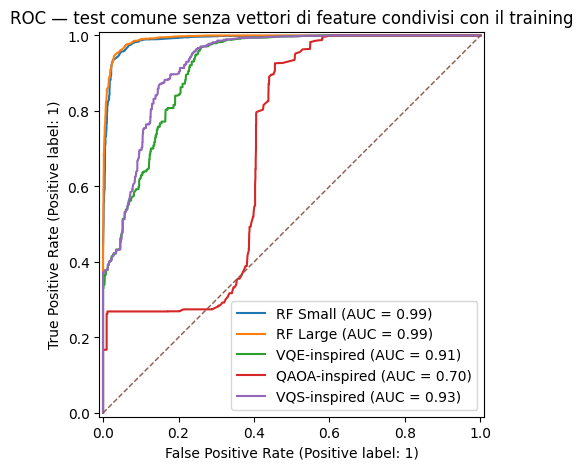

Modello con AUROC media più alta: RF Large
Confusion matrix relativa al modello Random Forest selezionato.


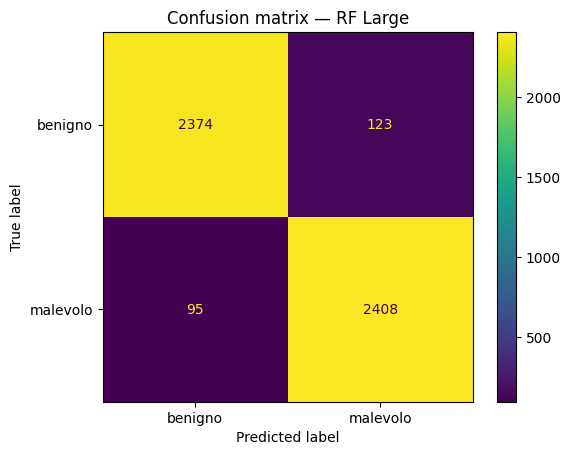

Migliore AUROC media: RF Large
              precision    recall  f1-score   support

     benigno       0.96      0.95      0.96      2497
    malevolo       0.95      0.96      0.96      2503

    accuracy                           0.96      5000
   macro avg       0.96      0.96      0.96      5000
weighted avg       0.96      0.96      0.96      5000



In [22]:
all_probs = {
    'RF Small': rf_small_prob,
    'RF Large': rf_large_prob,
    'VQE-inspired': vqe_prob,
    'QAOA-inspired': qaoa_prob,
    'VQS-inspired': vqs_prob
}
fig,ax=plt.subplots(figsize=(7,5))
for name,probs in all_probs.items():
    RocCurveDisplay.from_predictions(y_eval,probs,name=name,ax=ax)
ax.plot([0,1],[0,1],'--',linewidth=1)
ax.set_title(
    'ROC — test comune senza vettori di feature condivisi con il training'
)
plt.show()
best_name = summary.index[0]

best_probs = all_probs[best_name]

ConfusionMatrixDisplay(
    confusion_matrix(
        y_eval,
        best_probs >= 0.5,
        labels=[0, 1]
    ),
    display_labels=['benigno', 'malevolo']
).plot()
print(
    "Modello con AUROC media più alta:",
    best_name
)

if best_name in ['VQE-inspired', 'QAOA-inspired', 'VQS-inspired']:
    print("Confusion matrix relativa al seed:", SEEDS[0])
else:
    print("Confusion matrix relativa al modello Random Forest selezionato.")
    
plt.title(f'Confusion matrix — {best_name}')
plt.show()
print('Migliore AUROC media:',best_name)
print(classification_report(y_eval,best_probs>=.5,target_names=['benigno','malevolo'],zero_division=0))

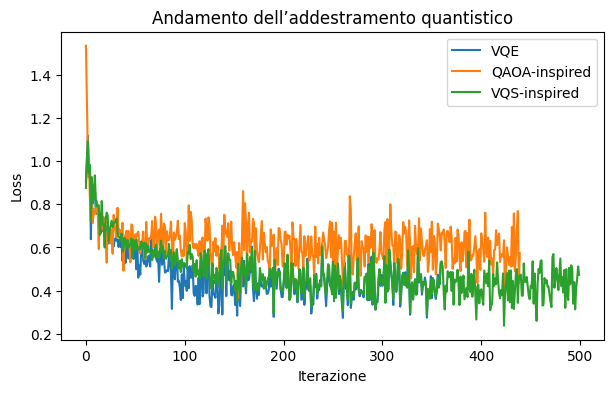

In [19]:
plt.figure(figsize=(7, 4))
plt.plot(vqe_loss_trace, label='VQE')
plt.plot(qaoa_loss_trace, label='QAOA-inspired')
plt.plot(vqs_loss_trace, label='VQS-inspired')
plt.xlabel('Iterazione')
plt.ylabel('Loss')
plt.title('Andamento dell’addestramento quantistico')
plt.legend()
plt.show()

9. Interpretazione dei risultati e limiti dello studio

9.1 Risultati sperimentali

Il confronto sperimentale mostra che la Random Forest ottiene le prestazioni complessive migliori nella classificazione dei segnali RF benigni e malevoli.

In particolare, RF Large raggiunge un’AUROC di circa 0,9927, mentre RF Small ottiene un’AUROC di circa 0,9900.

L’elevata capacità discriminativa delle Random Forest indica che le quattro feature selezionate contengono informazioni rilevanti per distinguere le due classi nel test utilizzato.

Tra i classificatori quantistici simulati, VQS-inspired ottiene l’AUROC media più elevata, pari a circa 0,9272, seguito da VQE-inspired con 0,9162 e QAOA-inspired con 0,6725.

VQS-inspired presenta inoltre un recall medio della classe malevola pari a circa 95,54%, vicino a quello di RF Small, pari a circa 95,77%.

Tuttavia, il valore inferiore di F1-score evidenzia un compromesso meno favorevole tra precision e recall, associato a una maggiore presenza di falsi positivi.

9.2 Stabilità rispetto ai seed

I classificatori quantistici vengono addestrati utilizzando cinque seed differenti: 42, 123, 2024, 2025 e 2026.

Le ripetizioni consentono di valutare la sensibilità dei modelli all’inizializzazione dei parametri e al campionamento dei minibatch.

VQS-inspired mostra la variabilità più contenuta dell’AUROC tra i tre approcci quantistici, mentre QAOA-inspired presenta oscillazioni più marcate.

Questi risultati suggeriscono una maggiore stabilità di VQS-inspired nella configurazione sperimentale considerata.

Le cinque ripetizioni non rappresentano tuttavia cinque dataset indipendenti, poiché training, validation e test rimangono invariati.

9.3 Costo computazionale

Le Random Forest richiedono tempi di addestramento notevolmente inferiori rispetto ai classificatori quantistici simulati.

I circuiti quantistici sono eseguiti mediante simulazione classica e richiedono numerose valutazioni del circuito durante il calcolo della loss e dei gradienti.

VQS-inspired introduce inoltre il costo aggiuntivo della stima periodica della metrica quantistica.

I tempi osservati dipendono dall’hardware, dall’implementazione e dalle librerie utilizzate. Non costituiscono quindi una misura diretta delle prestazioni ottenibili su hardware quantistico reale.

9.4 Limiti metodologici

Il dataset presenta un’elevata percentuale di osservazioni duplicate e alcune configurazioni di feature associate a etichette discordanti.

Per ridurre il rischio di leakage, lo split viene effettuato raggruppando i vettori di feature identici, impedendo la loro condivisione tra training, validation e test.

Questa procedura migliora l’affidabilità del confronto rispetto a uno split casuale delle singole righe.

Tuttavia, non essendo disponibili identificativi di sessione, dispositivo o acquisizione, non è possibile dimostrare la completa indipendenza delle osservazioni.

Il confronto viene inoltre effettuato utilizzando quattro feature selezionate, mentre un classificatore classico ottimizzato senza questo vincolo potrebbe beneficiare dell’utilizzo di ulteriori variabili.

I modelli quantistici hanno capacità parametrica differente: VQE-inspired e VQS-inspired utilizzano 24 parametri, mentre QAOA-inspired ne utilizza quattro.

Infine, i risultati sono ottenuti mediante simulazione classica dei circuiti quantistici e non dimostrano un vantaggio computazionale quantistico.

9.5 Conclusioni

I risultati indicano che, nelle condizioni sperimentali considerate, la Random Forest rappresenta la soluzione più efficace in termini di capacità discriminativa, equilibrio tra precision e recall e costo computazionale.

Tra i classificatori quantistici simulati, VQS-inspired ottiene le prestazioni migliori in termini di AUROC media e mostra una variabilità contenuta rispetto ai seed.

VQE-inspired presenta un comportamento relativamente stabile, mentre QAOA-inspired risulta meno competitivo nella configurazione utilizzata.

Lo studio costituisce un confronto sperimentale controllato tra metodi classici e classificatori quantistici simulati, ma non dimostra un vantaggio quantistico né garantisce la generalizzazione a nuove acquisizioni RF indipendenti.

Ulteriori sviluppi potrebbero includere la valutazione su sessioni di acquisizione indipendenti, l’analisi delle prestazioni per frequenza, l’ottimizzazione delle soglie decisionali e il confronto con ulteriori baseline classiche.